# 02 - Data check (deliverable 3)

Self-contained notebook that checks the four datasets written by `01_gen_data.ipynb`:

1. **Kirchhoff check** for each case: the four terminal currents (into the device) must sum to zero.
2. **Three trend plots**: OFF current vs temperature, OFF current vs vth0, and gate current vs toxe. Each trend must have the sign physics predicts.

Figures and the Kirchhoff table are saved to `results/`. Only the CSV files in `data/` are needed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"
RESULT_DIR.mkdir(exist_ok=True)

CASES = ["nmos_on", "nmos_off", "pmos_on", "pmos_off"]
CURRENTS = ["id", "ig", "is", "ib"]
missing = [c for c in CASES if not (DATA_DIR / f"{c}.csv").exists()]
if missing:
    raise FileNotFoundError(f"missing datasets {missing}: run 01_gen_data.ipynb first")
data = {c: pd.read_csv(DATA_DIR / f"{c}.csv") for c in CASES}
{c: d.shape for c, d in data.items()}

{'nmos_on': (10000, 16),
 'nmos_off': (10000, 16),
 'pmos_on': (10000, 16),
 'pmos_off': (10000, 16)}

## 1. Kirchhoff check
For every sample `id + ig + is + ib` must be zero. The solver floor is about 1e-15 A, so the criterion is an **absolute** residual of at most **1e-14 A** for every row.
A residual relative to the largest terminal current is also shown, but only for rows whose largest current is above 1e-12 A (below that the currents are of the order of the solver floor).

In [2]:
TOL = 1e-14
rows = []
for c, d in data.items():
    total = d[CURRENTS].sum(axis=1).abs()
    biggest = d[CURRENTS].abs().max(axis=1)
    rel = (total / biggest)[biggest > 1e-12]
    rows.append(dict(case=c, rows=len(d), max_abs_sum_A=total.max(), median_abs_sum_A=total.median(),
                     max_rel_sum=rel.max(), rows_above_tol=int((total > TOL).sum()), passes=bool((total <= TOL).all())))
kirchhoff = pd.DataFrame(rows)
kirchhoff.to_csv(RESULT_DIR / "kirchhoff_check.csv", index=False)
print(f"criterion: |sum of the four terminal currents| <= {TOL:g} A for every row")
kirchhoff

criterion: |sum of the four terminal currents| <= 1e-14 A for every row


,case,rows,max_abs_sum_A,median_abs_sum_A,max_rel_sum,rows_above_tol,passes
0,nmos_on,10000,1.547050e-15,8.993881e-17,4.080526e-04,0,True
1,nmos_off,10000,8.491653e-19,4.804346e-23,8.833799e-12,0,True
2,pmos_on,10000,9.844014e-16,3.237382e-17,6.433740e-05,0,True
3,pmos_off,10000,1.303776e-15,8.075884e-17,5.536957e-04,0,True


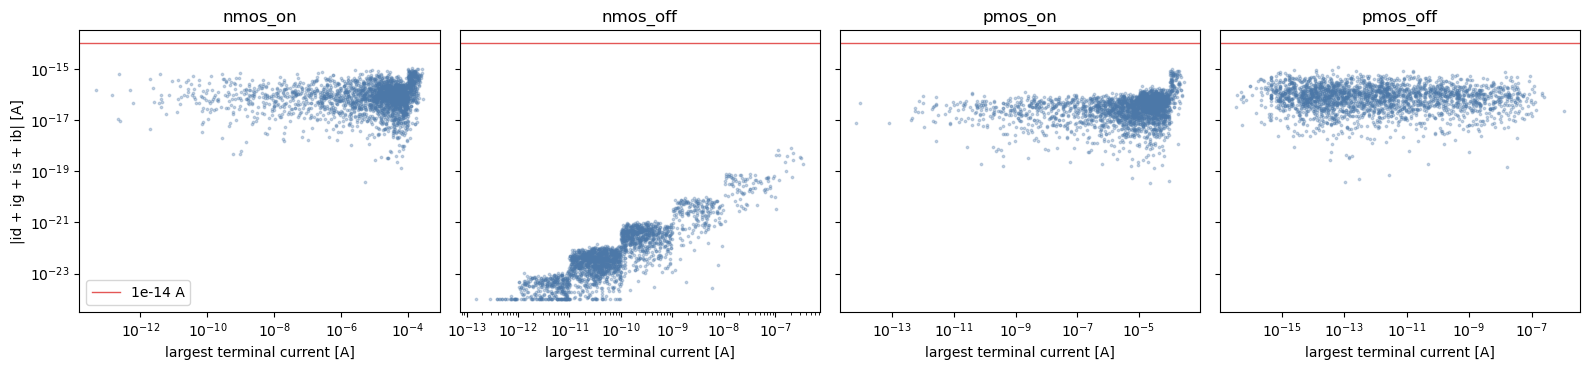

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for a, (c, d) in zip(ax, data.items()):
    total = d[CURRENTS].sum(axis=1).abs().clip(lower=1e-24)
    biggest = d[CURRENTS].abs().max(axis=1)
    sel = np.random.default_rng(0).choice(len(d), size=2500, replace=False)
    a.scatter(biggest.to_numpy()[sel], total.to_numpy()[sel], s=3, alpha=0.3, color="#4C78A8")
    a.axhline(TOL, color="#E45756", lw=1, label=f"{TOL:g} A")
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(c); a.set_xlabel("largest terminal current [A]")
ax[0].set_ylabel("|id + ig + is + ib| [A]")
ax[0].legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / "kirchhoff_check.png", dpi=110)
plt.show()

## 2. Trend plots
Every sample varies all parameters at once, so each plot shows all samples (dots) with the **binned median** and the 10-90 % band. The trend of the median must follow the physics.
* **OFF current** is the drain-current magnitude `|id|` of the OFF datasets, restricted to samples with `|Vd - Vs| >= 0.5 VDD`: at small `Vds` the current goes to zero whatever the temperature or vth0.
* **Gate current** is `|ig|` of all four datasets (no filter).

In [4]:
def binned(x, y, bins=20):
    """Median and 10-90 % band of y in equal-width bins of x."""
    x, y = np.asarray(x), np.asarray(y)
    edges = np.linspace(x.min(), x.max(), bins + 1)
    idx = np.clip(np.digitize(x, edges) - 1, 0, bins - 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    stats = np.array([np.percentile(y[idx == k], [50, 10, 90]) if (idx == k).sum() > 5 else [np.nan] * 3 for k in range(bins)])
    return centers, stats[:, 0], stats[:, 1], stats[:, 2]


def thin(n, k=2500, seed=0):
    """Indices of at most k points to draw (plots only; every statistic uses all rows)."""
    return np.random.default_rng(seed).choice(n, size=min(n, k), replace=False)


def trend_panel(ax, x, y, xlabel, title, color):
    x = np.asarray(x)
    ly = np.log10(np.abs(np.asarray(y)))
    sel = thin(len(x))
    ax.scatter(x[sel], ly[sel], s=3, alpha=0.25, color=color)
    cx, med, lo, hi = binned(x, ly)
    ax.fill_between(cx, lo, hi, color="black", alpha=0.12)
    ax.plot(cx, med, color="black", lw=2)
    ax.set_xlabel(xlabel); ax.set_title(title)


def off_samples(case):
    d = data[case]
    return d[(d.vd - d.vs).abs() >= 0.5 * d.vdd]


off = {c: off_samples(c) for c in ("nmos_off", "pmos_off")}
{c: len(d) for c, d in off.items()}

{'nmos_off': 2535, 'pmos_off': 2566}

### 2.1 OFF current vs temperature
Sub-threshold leakage grows with temperature (the threshold voltage falls and the thermal voltage rises), so the median of `log10|id|` must increase with T.

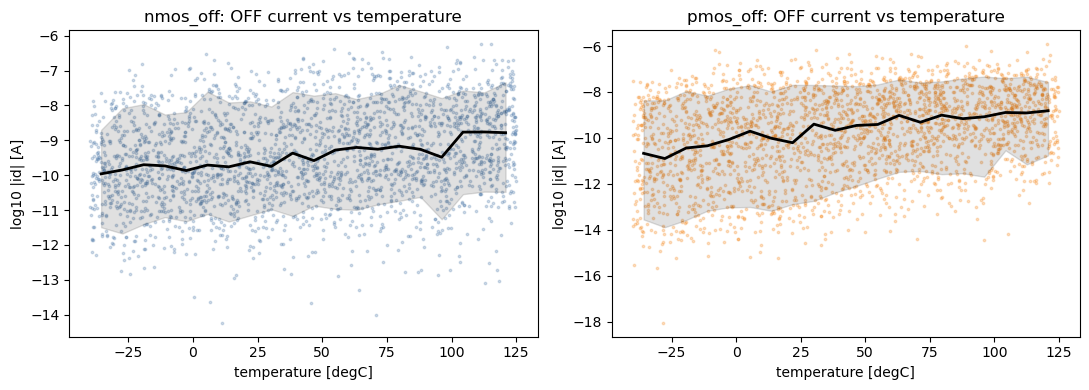

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for a, (c, color) in zip(ax, [("nmos_off", "#4C78A8"), ("pmos_off", "#F58518")]):
    trend_panel(a, off[c].temp, off[c].id, "temperature [degC]", f"{c}: OFF current vs temperature", color)
    a.set_ylabel("log10 |id| [A]")
fig.tight_layout()
fig.savefig(RESULT_DIR / "trend_off_vs_temp.png", dpi=110)
plt.show()

### 2.2 OFF current vs vth0
A higher threshold voltage magnitude means a lower sub-threshold current, so the median must fall with `|vth0|` (PMOS vth0 is negative, so its magnitude is used).

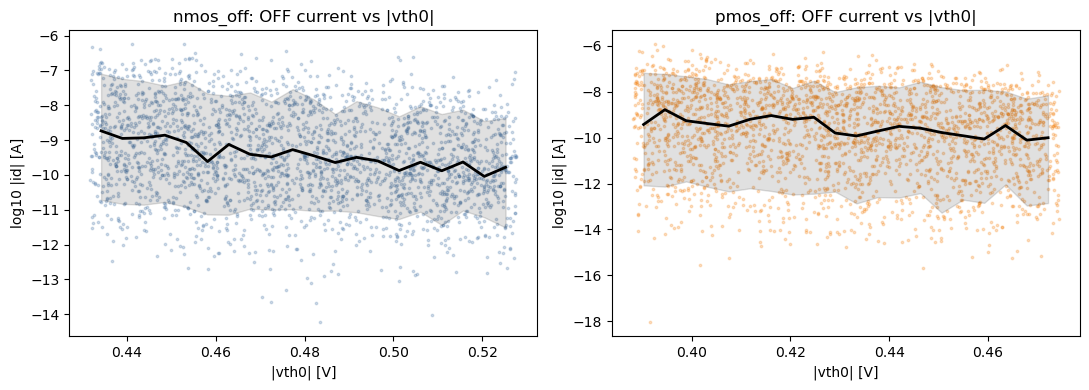

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (c, color) in zip(ax, [("nmos_off", "#4C78A8"), ("pmos_off", "#F58518")]):
    trend_panel(a, off[c].vth0.abs(), off[c].id, "|vth0| [V]", f"{c}: OFF current vs |vth0|", color)
    a.set_ylabel("log10 |id| [A]")
fig.tight_layout()
fig.savefig(RESULT_DIR / "trend_off_vs_vth0.png", dpi=110)
plt.show()

### 2.3 Gate current vs toxe
Direct tunnelling through the gate oxide falls steeply as the oxide gets thicker, so the median of `log10|ig|` must fall with `toxe` in every case.

C:\Users\riins\AppData\Local\Temp\ipykernel_1200\1742448447.py:18: RuntimeWarning: divide by zero encountered in log10
  ly = np.log10(np.abs(np.asarray(y)))
C:\Users\riins\anaconda3\Lib\site-packages\numpy\lib\function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


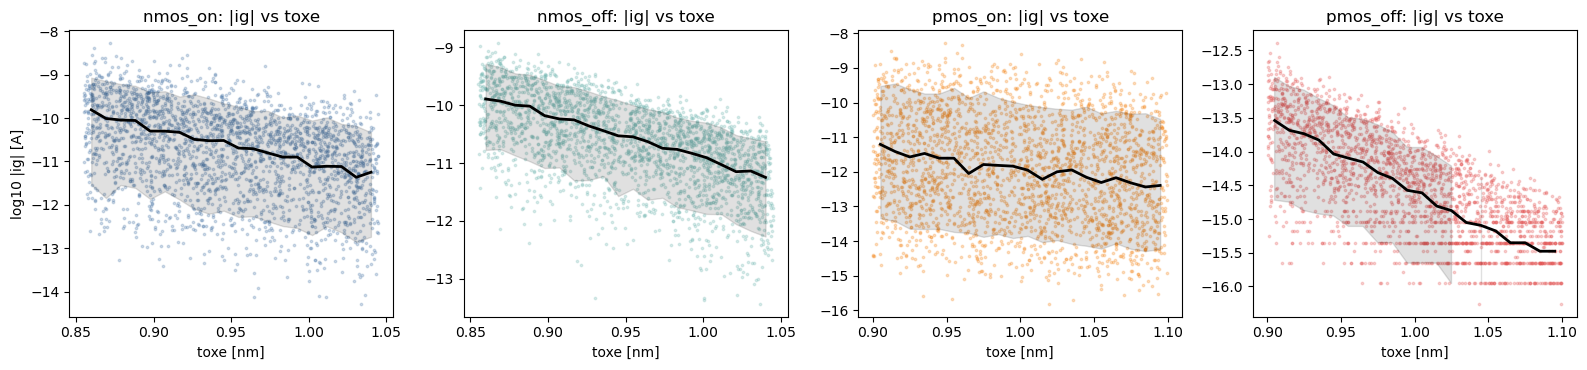

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for a, (c, color) in zip(ax, zip(CASES, ["#4C78A8", "#72B7B2", "#F58518", "#E45756"])):
    trend_panel(a, data[c].toxe * 1e9, data[c].ig, "toxe [nm]", f"{c}: |ig| vs toxe", color)
ax[0].set_ylabel("log10 |ig| [A]")
fig.tight_layout()
fig.savefig(RESULT_DIR / "trend_ig_vs_toxe.png", dpi=110)
plt.show()

### 2.4 Do the trends have the expected sign?
Spearman rank correlation between the parameter and `log10|current|` (all other parameters vary freely, so only the sign and rough size are meaningful).

In [8]:
checks = []
for c in ("nmos_off", "pmos_off"):
    checks.append((c, "temperature", off[c].temp, off[c].id, +1))
    checks.append((c, "|vth0|", off[c].vth0.abs(), off[c].id, -1))
for c in CASES:
    checks.append((c, "toxe -> |ig|", data[c].toxe, data[c].ig, -1))
rows = []
for c, name, x, y, expected in checks:
    rho = spearmanr(x, np.log10(np.abs(y))).statistic
    rows.append(dict(case=c, relation=name, spearman=round(float(rho), 3), expected_sign="+" if expected > 0 else "-",
                     as_expected=bool(np.sign(rho) == expected)))
trends = pd.DataFrame(rows)
trends.to_csv(RESULT_DIR / "trend_check.csv", index=False)
trends

C:\Users\riins\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,case,relation,spearman,expected_sign,as_expected
0,nmos_off,temperature,0.235,+,True
1,nmos_off,|vth0|,-0.218,-,True
2,pmos_off,temperature,0.297,+,True
3,pmos_off,|vth0|,-0.153,-,True
4,nmos_on,toxe -> |ig|,-0.399,-,True
5,nmos_off,toxe -> |ig|,-0.597,-,True
6,pmos_on,toxe -> |ig|,-0.184,-,True
7,pmos_off,toxe -> |ig|,-0.683,-,True


## Result
* Kirchhoff: see the table in section 1 (every case must show `passes = True`).
* Trends: every row of the table above must show `as_expected = True`.
* Files written to `results/`: `kirchhoff_check.csv`, `kirchhoff_check.png`, `trend_check.csv`, `trend_off_vs_temp.png`, `trend_off_vs_vth0.png`, `trend_ig_vs_toxe.png`.